# 台股訊號家族：歷史資料品質與驗證覆蓋

## tl;dr

截至 2026-10-04，行情與法人流最新交易日仍是 2026-10-02：行情表有 6,050,865 列、4,172 個資料日、1,946 個代碼；另有 63 列落在異常的 `0114`/`0115` 年份，與直接加 1911 年後的同股同日鍵完全對不上，來源尚未查明，暫不納入回測。10/2 行情覆蓋上市 1,050/1,054、上櫃 888/892；上櫃列有 20 筆收盤價為空，可用收盤數為 868。法人流同日匹配上市 1,043、上櫃 788，另有 22,966 列 unmatched，不當零量或可確認個股覆蓋。

成熟 outcome 仍只有 2026-09-24 一個訊號日。以較接近可執行的 `next_close` 一交易日窗看，上市量能家族為 15/20 方向命中、平均家族方向調整後超額報酬 +3.817 個百分點；上櫃為 6/21、-1.197 個百分點。這是批次家族診斷的新觀察候選，不是穩定預測：兩種市場都只有同一訊號日、候選家族互相重疊、報酬未扣成本/除權息，因此不改方向門檻或權重。

## Context & Methods

### Key Assumptions

- 行情與法人流以 `(資料日期, 證券代號)` 為檢查粒度；市場母體來自 `全證券代碼相關資料表`。
- 未匹配上市/上櫃主檔的法人流列保留為 `unmatched`，不當成零量或個股訊號。
- 來源表的 accepted / rejected / duplicate 是收集品質；是否涵蓋上市與上櫃仍另查有效個股數。
- `market_signal_outcomes` 是候選結果。相同日期的多檔候選彼此相關；單一日期樣本不等於跨期驗證。
- `signal_close` 是收盤後通知的事後描述基準；`next_close` 是較保守的可執行代理，兩者尚未扣交易成本。
- 券商研究只在授權、全市場批次端點、PIT 時間/版本及上市櫃覆蓋可確認時納入，不把逐家公司人工調查列入自動訊號回測。

### Source and execution

資料取自本機 Docker Compose 的 Airflow scheduler 連線設定，僅執行 `SELECT`。來源是 `stock.個股成交資訊`、`stock.三大法人買賣`、`stock.全證券代碼相關資料表` 及 `crawler.source_records`、`source_runs`、`market_signal_runs`、`market_signal_outcomes`。

最新每日掃描程式會在 outcome ledger 提交後，將最近 120 日的成熟訊號家族摘要放進 `family_outcome_diagnostics` XCom；自然 run 的 XCom 回執仍待下次收盤子 run 驗證。本 notebook 對原始候選家族與 outcome 再做唯讀彙總，保留可重跑的歷史檢視。

從 `D:\DataFlow` 執行此 notebook；需有啟動中的 `airflow-scheduler` 容器及本機 Python 套件 `nbformat`、`nbclient`、`pandas`、`matplotlib`。容器自行讀取已配置連線資訊，筆記不保存憑證。

## Data

### 1. 唯讀盤點

查詢輸出限制為期間摘要、最新有效日、最近日上市/上櫃覆蓋、近期重複鍵、日線候選日期及已成熟 outcome。執行容器內查詢前不顯示或複製連線設定。

In [1]:
from pathlib import Path
import json
import subprocess
import pandas as pd

QUERY_SCRIPT = Path("docs/stock_signal_family_history_queries.py").read_text(encoding="utf-8")
result = subprocess.run(
    ["docker", "compose", "exec", "-T", "airflow-scheduler", "python", "-"],
    input=QUERY_SCRIPT, text=True, encoding="utf-8", capture_output=True, cwd=Path.cwd(), check=True, timeout=180,
)
data = json.loads(result.stdout)
print("Read-only database snapshot loaded.")

Read-only database snapshot loaded.


### 2. 來源歷史與收集狀態

In [2]:
history = pd.DataFrame(data["stock_history"])
old_dates = pd.DataFrame(data["pre_2014_date_buckets"])
if old_dates.empty:
    old_counts = pd.DataFrame(columns=["dataset", "pre_2014_rows_n", "pre_2014_years_n"])
else:
    old_counts = old_dates.groupby("dataset", as_index=False).agg(pre_2014_rows_n=("rows_n", "sum"), pre_2014_years_n=("stored_year", "nunique"))
history.merge(old_counts, on="dataset", how="left")

dataset,min_date,max_date,pre_2014_rows_n,pre_2014_years_n
daily_price,0114-02-24,2026-10-02,975290.0,6.0
institutional_flow,2014-12-01,2026-10-02,NaN,NaN


#### Check the anomalous early-year keys

In [3]:
pd.DataFrame(data["pre_1000_shifted_key_check"])

dataset,stored_year,rows_n,codes_n,keys_also_present_at_roc_plus_1911_n
daily_price,114,39,39,0
daily_price,115,24,24,0


In [4]:
pd.DataFrame(data["source_history"])

source_key,event_type,quality_status,rows_n,entities_n,effective_dates_n,min_effective,max_effective,min_event_time,max_event_time
tpex_director_holdings_monthly,director_holding_snapshot,ok,17139,891,1,2026-08-01,2026-08-01,2026-09-18 00:00:00,2026-09-18 00:00:00
tpex_market_index_daily,market_index_daily,ok,22,1,22,2026-09-01,2026-10-02,2026-09-01 00:00:00,2026-10-02 00:00:00
tpex_monthly_revenue,monthly_revenue,ok,2673,894,3,2026-06-01,2026-08-01,2026-07-17 00:00:00,2026-09-17 00:00:00
tpex_quarterly_profitability,quarterly_profitability,ok,885,885,1,2026-06-30,2026-06-30,2026-10-01 00:00:00,2026-10-02 00:00:00
twse_director_holdings_monthly,director_holding_snapshot,ok,26804,1084,1,2026-08-01,2026-08-01,2026-09-18 00:00:00,2026-09-18 00:00:00
twse_market_index_daily,market_index_daily,ok,21,1,21,2026-09-01,2026-10-01,2026-09-01 00:00:00,2026-10-01 00:00:00
twse_monthly_revenue,monthly_revenue,ok,3253,1087,3,2026-06-01,2026-08-01,2026-07-17 00:00:00,2026-09-17 00:00:00
twse_quarterly_forecast_attainment,company_forecast_attainment_observation,quarantine,8,6,1,2026-06-30,2026-06-30,2026-10-01 00:00:00,2026-10-01 00:00:00
twse_quarterly_forecast_variance,company_forecast_variance,ok,14,5,1,2026-06-30,2026-06-30,2026-10-01 00:00:00,2026-10-01 00:00:00
twse_quarterly_profitability,quarterly_profitability,ok,1049,1049,1,2026-06-30,2026-06-30,2026-10-02 00:00:00,2026-10-02 00:00:00


In [5]:
pd.DataFrame(data["source_runs_latest"])

source_key,started_at,finished_at,status,row_count,accepted_count,rejected_count,duplicate_count,dag_id,task_id
tpex_market_index_daily,2026-10-02 12:00:05,2026-10-02 12:00:06,success,2,2,0,0,None,ingest_approved_source
tpex_monthly_revenue,2026-10-02 14:45:07,2026-10-02 14:45:08,success,892,892,0,0,source_extension_collect_intraday,ingest_approved_source
twse_market_index_daily,2026-10-02 12:00:08,2026-10-02 12:00:08,success,1,1,0,0,None,ingest_approved_source
twse_monthly_revenue,2026-10-02 14:45:07,2026-10-02 14:45:09,success,1086,1086,0,0,source_extension_collect_intraday,ingest_approved_source
twse_quarterly_forecast_attainment,2026-10-02 12:00:05,2026-10-02 12:00:06,success,8,0,8,0,None,ingest_approved_source
twse_quarterly_forecast_variance,2026-10-02 14:45:09,2026-10-02 14:45:09,success,7,7,0,0,source_extension_collect_intraday,ingest_approved_source


### 3. 最新日線與法人流覆蓋

將可用收盤列與上市/上櫃主檔數量並列。法人流另列未匹配列；這些列不屬於可確認的個股涵蓋。

In [6]:
universe = pd.DataFrame(data["market_universe"])
prices = pd.DataFrame(data["latest_price_coverage"])
flows = pd.DataFrame(data["latest_flow_coverage"])
price_market = prices[prices["market"] != "unmatched"].copy()
price_market = price_market.merge(universe[["market", "master_codes_n"]], on="market", how="left")
for column in ("rows_n", "null_close_n", "master_codes_n"):
    price_market[column] = pd.to_numeric(price_market[column])
price_market["usable_close_n"] = price_market["rows_n"] - price_market["null_close_n"]
price_market[["trade_date", "market", "usable_close_n", "rows_n", "null_close_n", "master_codes_n"]]

trade_date,market,usable_close_n,rows_n,null_close_n,master_codes_n
2026-10-02,上市,1050,1050,0,1054
2026-10-02,上櫃,868,888,20,892


In [7]:
flows

trade_date,market,rows_n,codes_n,null_total_n,null_foreign_n
2026-10-02,unmatched,22966,22966,0,0
2026-10-02,上市,1043,1043,0,0
2026-10-02,上櫃,788,788,0,0


cell-8:14: UserWarning: FigureCanvasAgg is non-interactive, and thus cannot be shown


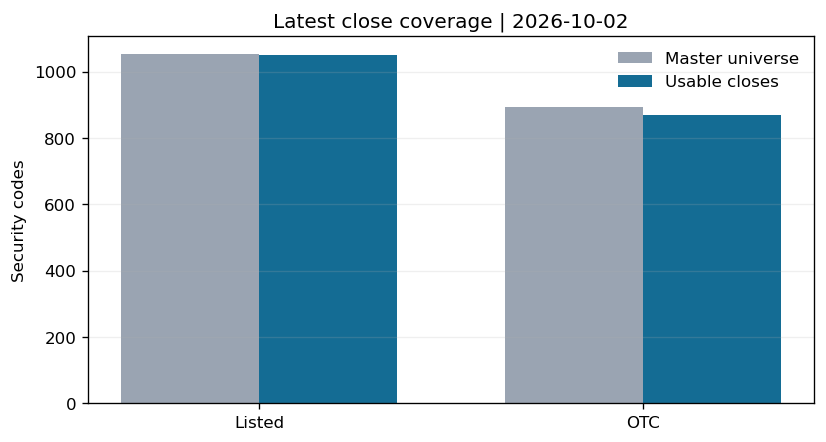

In [8]:
import matplotlib.pyplot as plt

fig, ax = plt.subplots(figsize=(7, 3.8))
labels = price_market["market"].map({"\u4e0a\u5e02": "Listed", "\u4e0a\u6ac3": "OTC"}).tolist()
positions = range(len(labels))
ax.bar([p - 0.18 for p in positions], price_market["master_codes_n"], width=0.36, label="Master universe", color="#9aa4b2")
ax.bar([p + 0.18 for p in positions], price_market["usable_close_n"], width=0.36, label="Usable closes", color="#146c94")
ax.set_xticks(list(positions), labels)
ax.set_ylabel("Security codes")
ax.set_title(f"Latest close coverage | {price_market['trade_date'].iloc[0]}")
ax.legend(frameon=False)
ax.grid(axis="y", alpha=0.2)
plt.tight_layout()
plt.show()

### 4. 日線候選與 outcome 成熟樣本

In [9]:
pd.DataFrame(data["daily_signal_runs"])[["as_of_date", "status", "source_status", "universe_count", "price_count", "flow_count", "revenue_count", "financial_count", "candidate_count", "started_at"]]

as_of_date,status,source_status,universe_count,price_count,flow_count,revenue_count,financial_count,candidate_count,started_at
2026-10-02,ready,partial,1946,1938,1891,1945,1902,50,2026-10-02 20:02:35
2026-09-24,ready,fresh,1947,1940,1893,1946,1903,81,2026-09-26 22:38:17
None,failed,unknown,0,0,0,0,0,0,2026-09-25 20:00:15


In [10]:
pd.DataFrame(data["outcomes"])

outcome_basis,horizon_sessions,status,source_status,rows_n,candidates_n,min_signal_date,max_signal_date,hit_scored_n,directional_hit_rate,mean_excess_return_pp
next_close,1,settled,fresh,81,81,2026-09-24,2026-09-24,80,0.4625,0.9867925062
signal_close,1,settled,fresh,81,81,2026-09-24,2026-09-24,80,0.6250,1.7759667901


### 訊號家族方向歸因

以候選當時保存的 `family_directions`，將每個成熟的市場相對超額報酬投影到各家族方向，分市場、資料狀態、進出場基準及持有期彙總。家族會在同一候選中重疊，結果是描述性歸因，不代表因果效果；報酬仍未調整除權息與交易成本。

In [ ]:
family_attribution = pd.DataFrame(data["family_attribution"])
family_attribution

In [ ]:
data["family_attribution_note"]

In [11]:
pd.DataFrame(data["recent_duplicate_grain"])

Empty DataFrame
Columns: []
Index: []

## Results

### 歷史範圍與鍵值品質

- `stock.個股成交資訊` 共 6,050,865 列、4,172 個資料日、1,946 個代碼，最大資料日 2026-10-02。文字日期範圍最早顯示 `0114-02-24`；其中 39 列落在 `0114` 年、24 列落在 `0115` 年。兩組共 63 個代碼/日期鍵，逐一檢查同代碼 `+1911 年`後均沒有對應鍵。早期年度可能是日期解析/載入異常，但成因未證實；不自動轉換、不用於長期回測。
- 另有較早的 2009–2013 行情資料。全期間及近 18 日 `(資料日期, 證券代號)` 重複鍵查詢均未發現重複；這不會消除日期解析異常或缺漏風險。
- `stock.三大法人買賣` 共 33,672,125 列、2,829 個資料日，涵蓋 2014-12-01 至 2026-10-02。資料列的代碼種類含大量無法匹配證券主檔的值，不能把其代碼數當作個股覆蓋數。

### 2026-10-02 最新日覆蓋

| 家族 | 上市 | 上櫃 | 其他/限制 |
|---|---:|---:|---|
| 日行情列/代碼 | 1,050 / 1,054 | 888 / 892 | 上市收盤價空值 0；上櫃收盤價空值 20，可用收盤 868；兩邊成交量空值 0 |
| 法人流匹配證券 | 1,043 | 788 | 另有 22,966 列 unmatched；不轉成零量 |
| 月營收有效月份 | 2026-06 至 2026-08 | 2026-06 至 2026-08 | 最新批次來源接受 1,086/1,086 與 892/892、隔離均 0；月份數仍只有 3，不等於長期覆蓋 |
| 季獲利率 | 2026Q2 | 2026Q2 | 最新來源列 1,049/1,054 接受、隔離 5；上櫃 884 列接受。有效期仍為 6/30 |
| 董監持股 | 2026-08 | 2026-08 | 只有一個有效月份 |
| 市場指數基準 | 10/1 | 10/2 | TWSE 落後行情日一日，TPEx 到 10/2；故 10/2 日線 run 為 `ready/partial`，不能把來源成功等於 benchmark 完整 |

10/2 日線快照為 1,946 檔母體、1,938 檔行情、1,891 檔法人流、50 個候選、0 個通知。上櫃個股行情與基準來源的有效日/覆蓋仍須分開檢查。來源接受數滿額也不代表全市場覆蓋；來源成功狀態更不能替代有效日期。

### Outcome 成熟度

- 目前僅 `signal_date=2026-09-24` 有成熟 outcome；`signal_close` 與 `next_close` 各 81 列，各有 80 列方向結果。`next_close` 命中 46.25%、平均超額報酬 +0.98679 個百分點；`signal_close` 命中 62.5%、平均超額報酬 +1.77597 個百分點。
- 這些候選共享同一個市場日，彼此不獨立。`signal_close` 不是收盤後可實際成交的入場價，兩種結果尚未扣成本；不能據此宣稱預測勝率或調參。
- 2026-10-02 有 50 個候選，但下一交易日結果尚未成熟。需要累積多個不同訊號日、固定持有期、基準對齊與成本處理後，才可比較家族/通知品質。

### 自動來源資格

券商預估資料只作全市場批次 feed 候選。進入訊號與回測前，程式化驗收需有可確認授權、上市櫃覆蓋、來源發布/有效時間、可重建的歷史版本，以及可儲存和回測的權利；缺一項就保留為來源缺口，不以逐家公司網頁搜尋或人工評分補位。


## Takeaways

目前瓶頸是可用且日期正確的跨市場快照，以及多訊號日成熟 outcome，不是原始列數不足。下一個自然收盤批次要逐來源核 effective date、raw/accepted/quarantined、上市/上櫃代碼覆蓋，特別確認 TPEx 個股行情和 TWSE 指數是否追上 10/2。保留 63 筆早期異常鍵待追來源，不把 unmatched 法人流當零。

研究整理上，官方事實、媒體背景、券商分析、反方證據與未知事項分欄；只有公開標題/摘要的研究不做方向票。報告預測應在後續資料到齊後逐項核驗。新增高品質訊號先以可檢驗假設與多日樣本累積，暫不因單一日期表現調整既有通知門檻。